In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
df = pd.read_csv('/content/credit_risk_dataset.csv')

In [18]:
df.head(5)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [19]:
df.shape

(32581, 12)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [21]:
#generate descriptive statics for dateframe
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [26]:
for col in ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']:
  print(df[col].value_counts())
  print("----")

person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64
----
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64
----
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64
----
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64
----


In [27]:
print(df.duplicated().sum())

165


In [28]:
print(df['loan_status'].value_counts())
print(df['loan_status'].value_counts(normalize=True) * 100)

loan_status
0    25473
1     7108
Name: count, dtype: int64
loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64


In [29]:
df_clean = df.copy()

In [30]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("Removed:", before - len(df_clean), "rows")
print("Rows now:", len(df_clean))

Removed: 165 rows
Rows now: 32416


In [31]:
before = len(df_clean)
df_clean = df_clean[df_clean['person_age'] <= 100]
df_clean = df_clean[(df_clean['person_emp_length'] <= 60) | (df_clean['person_emp_length'].isnull())]
print("Removed:", before - len(df_clean), "rows")
print("Rows now:", len(df_clean))

Removed: 7 rows
Rows now: 32409


In [32]:
print(df_clean[df_clean['person_income'] > 500000][['person_age','person_income','loan_amnt','loan_status']])
print(len(df_clean[df_clean['person_income'] > 500000]))

       person_age  person_income  loan_amnt  loan_status
17833          32        1200000      12000            0
17834          34         948000       2000            0
17840          35         648000      10000            1
17846          30         504000       3000            0
18635          31         636000      17500            0
18917          35         510000       1800            0
21462          33         612000       5950            0
21958          34         564000       6000            0
23429          31         552000       8000            0
23431          30         648000       8000            0
25714          32         703800      12000            1
27798          32         572400      16000            0
27877          30         522000       2500            0
27881          28         604000      25000            1
27882          31         741600      12000            0
27883          32         750000      30000            0
27884          35         76200

In [33]:
df_clean['person_emp_length'] = df_clean['person_emp_length'].fillna(df_clean['person_emp_length'].median())
df_clean['loan_int_rate'] = df_clean['loan_int_rate'].fillna(df_clean['loan_int_rate'].median())
print(df_clean.isnull().sum())

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


In [34]:
print(df_clean.shape)


(32409, 12)


In [35]:
df_clean['age_group'] = pd.cut(
    df_clean['person_age'],
    bins=[0, 25, 30, 35, 45, 100],
    labels=['Up to 25', '26-30', '31-35', '36-45', '46+']
)


In [36]:
df_clean['income_band'] = pd.cut(
    df_clean['person_income'],
    bins=[0, 30000, 50000, 75000, 100000, float('inf')],
    labels=['Under 30K', '30-50K', '50-75K', '75-100K', 'Above 100K']
)

In [37]:
df_clean['loan_amount_band'] = pd.cut(
    df_clean['loan_amnt'],
    bins=[0, 5000, 10000, 15000, 20000, 35000],
    labels=['Up to 5K', '5-10K', '10-15K', '15-20K', '20K+']
)

In [38]:
df_clean['burden_band'] = pd.cut(
    df_clean['loan_percent_income'],
    bins=[-0.01, 0.10, 0.20, 0.30, 1],
    labels=['Low (under 10%)', 'Moderate (10-20%)', 'High (20-30%)', 'Very High (30%+)']
)

In [39]:
df_clean['risk_bucket'] = df_clean['loan_grade'].map({
    'A': 'Low Risk', 'B': 'Low Risk',
    'C': 'Medium Risk', 'D': 'Medium Risk',
    'E': 'High Risk', 'F': 'High Risk', 'G': 'High Risk'
})

In [40]:
df_clean['loan_outcome'] = df_clean['loan_status'].map({0: 'Repaid', 1: 'Defaulted'})

In [41]:
for col in ['risk_bucket', 'age_group', 'income_band', 'burden_band', 'person_home_ownership']:
    print(df_clean.groupby(col, observed=True)['loan_status'].mean().mul(100).round(1))
    print('-----')

risk_bucket
High Risk      67.4
Low Risk       13.1
Medium Risk    34.5
Name: loan_status, dtype: float64
-----
age_group
Up to 25    23.1
26-30       20.9
31-35       20.2
36-45       20.7
46+         22.3
Name: loan_status, dtype: float64
-----
income_band
Under 30K     45.6
30-50K        25.7
50-75K        17.6
75-100K       11.0
Above 100K     9.6
Name: loan_status, dtype: float64
-----
burden_band
Low (under 10%)      11.8
Moderate (10-20%)    15.1
High (20-30%)        22.0
Very High (30%+)     70.4
Name: loan_status, dtype: float64
-----
person_home_ownership
MORTGAGE    12.6
OTHER       31.1
OWN          7.5
RENT        31.6
Name: loan_status, dtype: float64
-----


In [42]:
# 1. Income cap (new column, original kept safe)
cap = df_clean['person_income'].quantile(0.99)
print("Rows above 500,000:", (df_clean['person_income'] > 500000).sum())
print("99th percentile income:", cap)
df_clean['income_capped'] = df_clean['person_income'].clip(upper=cap)

# 2. Label cleanup
df_clean['loan_intent'] = df_clean['loan_intent'].replace({
    'DEBTCONSOLIDATION': 'Debt Consolidation',
    'HOMEIMPROVEMENT': 'Home Improvement',
    'EDUCATION': 'Education',
    'MEDICAL': 'Medical',
    'VENTURE': 'Venture',
    'PERSONAL': 'Personal'
})
df_clean['person_home_ownership'] = df_clean['person_home_ownership'].str.title()
df_clean['cb_person_default_on_file'] = df_clean['cb_person_default_on_file'].replace({'Y': 'Yes', 'N': 'No'})

# 3. Check
print(df_clean.shape)
print(df_clean['loan_intent'].unique())
print(df_clean['person_home_ownership'].unique())
print(df_clean['cb_person_default_on_file'].unique())

Rows above 500,000: 51
99th percentile income: 225000.0
(32409, 19)
['Education' 'Medical' 'Venture' 'Personal' 'Home Improvement'
 'Debt Consolidation']
['Own' 'Mortgage' 'Rent' 'Other']
['No' 'Yes']


In [43]:
print(df_clean.isnull().sum())
print(df_clean.columns.tolist())

for col in ['risk_bucket', 'age_group', 'income_band', 'burden_band', 'person_home_ownership']:
    print(df_clean.groupby(col, observed=True)['loan_status'].mean().mul(100).round(1))
    print('-----')

df_clean.to_csv("banking_risk_clean.csv", index=False)

# Download it from Google Colab to your computer
from google.colab import files
files.download("banking_risk_clean.csv")


person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
age_group                     0
income_band                   0
loan_amount_band              0
burden_band                   0
risk_bucket                   0
loan_outcome                  0
income_capped                 0
dtype: int64
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'age_group', 'income_band', 'loan_amount_band', 'burden_band', 'risk_bucket', 'loan_outcome', 'income_capped']
risk_bucket
High Risk      67.4
Lo

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

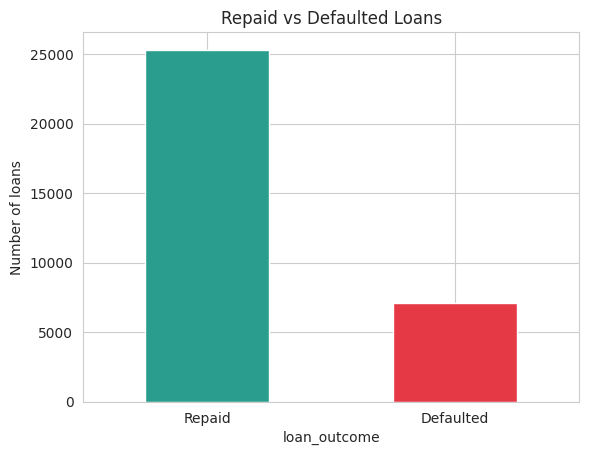

In [45]:
df_clean['loan_outcome'].value_counts().plot(kind='bar', color=['#2a9d8f', '#e63946'])
plt.title("Repaid vs Defaulted Loans")
plt.ylabel("Number of loans")
plt.xticks(rotation=0)
plt.show()

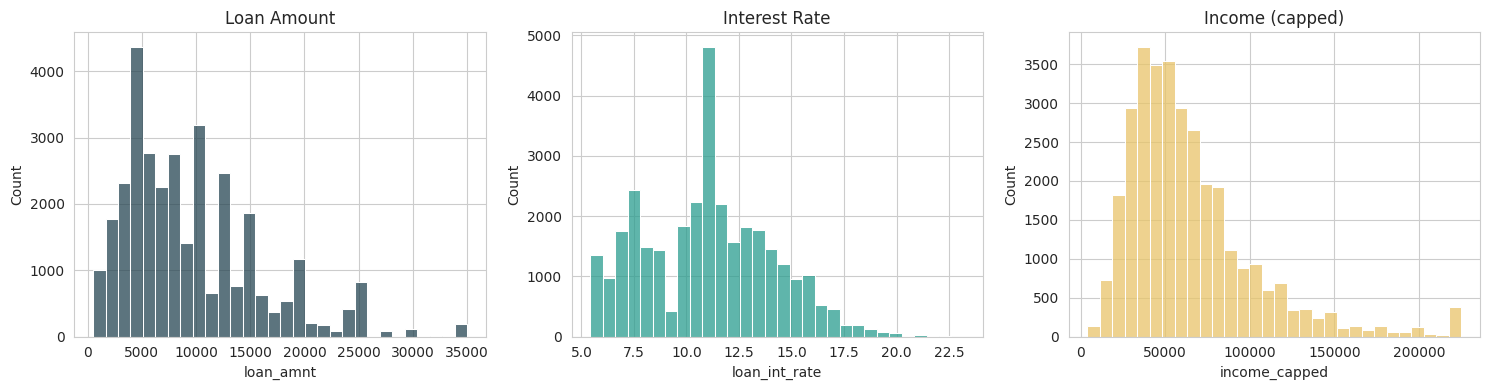

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df_clean['loan_amnt'], bins=30, ax=axes[0], color='#264653')
sns.histplot(df_clean['loan_int_rate'], bins=30, ax=axes[1], color='#2a9d8f')
sns.histplot(df_clean['income_capped'], bins=30, ax=axes[2], color='#e9c46a')
axes[0].set_title("Loan Amount")
axes[1].set_title("Interest Rate")
axes[2].set_title("Income (capped)")
plt.tight_layout()
plt.show()

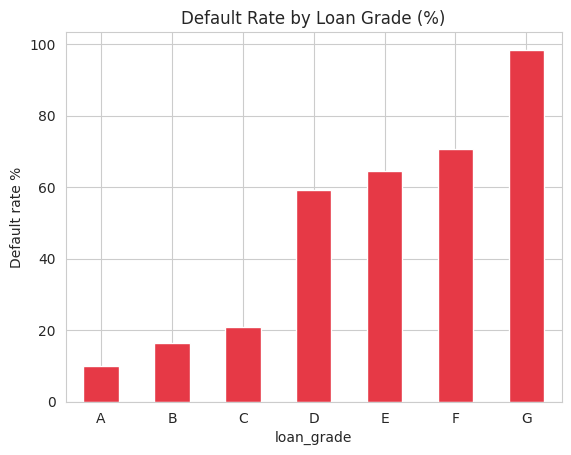

In [47]:
grade_default = df_clean.groupby('loan_grade')['loan_status'].mean().mul(100)
grade_default.plot(kind='bar', color='#e63946')
plt.title("Default Rate by Loan Grade (%)")
plt.ylabel("Default rate %")
plt.xticks(rotation=0)
plt.show()

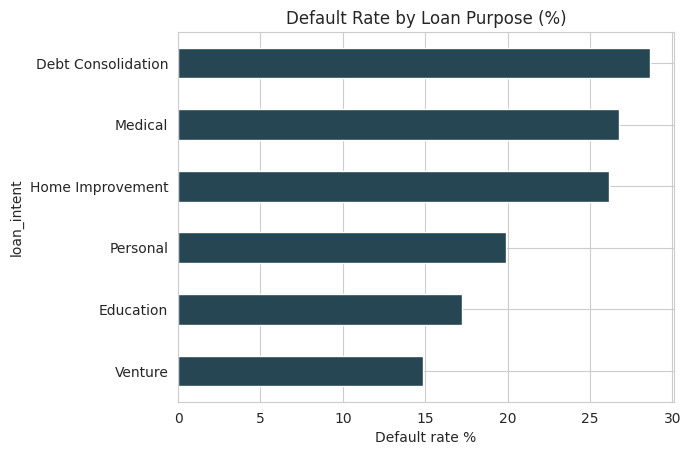

In [48]:
intent_default = df_clean.groupby('loan_intent')['loan_status'].mean().mul(100).sort_values()
intent_default.plot(kind='barh', color='#264653')
plt.title("Default Rate by Loan Purpose (%)")
plt.xlabel("Default rate %")
plt.show()

In [49]:
print(df_clean.groupby('cb_person_default_on_file')['loan_status'].mean().mul(100).round(1))

cb_person_default_on_file
No     18.4
Yes    37.9
Name: loan_status, dtype: float64


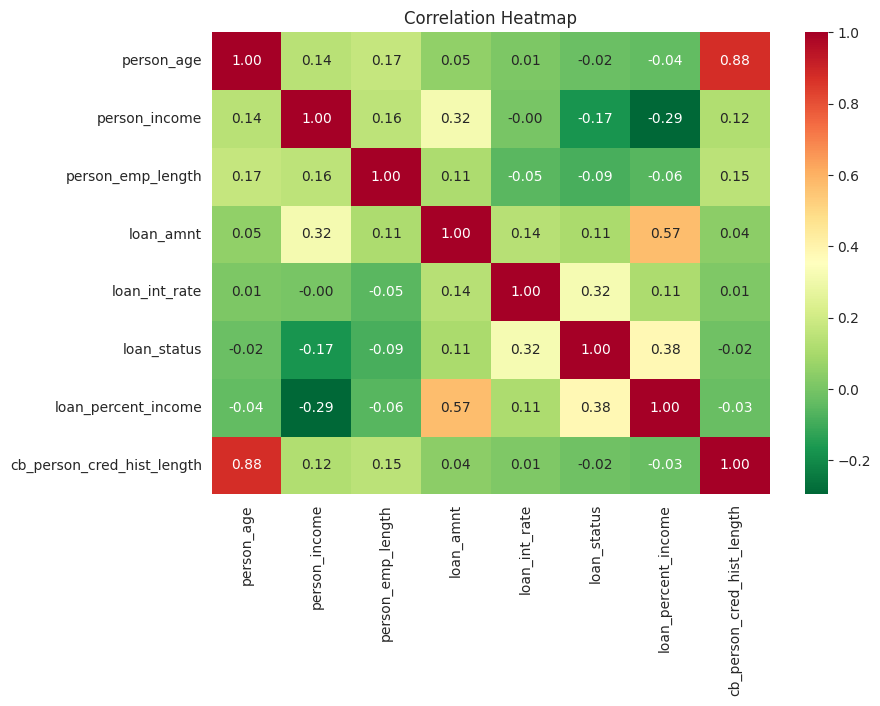

In [50]:
num_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
            'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_cred_hist_length']
plt.figure(figsize=(9, 6))
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt=".2f", cmap="RdYlGn_r")
plt.title("Correlation Heatmap")
plt.show()

In [51]:
df_clean.to_csv("banking_risk_clean.csv", index=False)
from google.colab import files
files.download("banking_risk_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
# Sort-order columns so Power BI shows bands in the right order
for col in ['age_group', 'income_band', 'loan_amount_band', 'burden_band']:
    df_clean[col + '_order'] = df_clean[col].cat.codes + 1

df_clean['risk_order'] = df_clean['risk_bucket'].map({'Low Risk': 1, 'Medium Risk': 2, 'High Risk': 3})

df_clean.to_csv("banking_risk_clean.csv", index=False)
from google.colab import files
files.download("banking_risk_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>